# Bayesian Linear Regression: Zellner's $g$-Prior, Exact Composition Sampling & Gibbs Variable Selection
## Logistics Daily Demand Forecasting Case Study

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)
[![Python 3.10+](https://img.shields.io/badge/Python-3.10%2B-blue.svg)](https://www.python.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](https://opensource.org/licenses/MIT)

---

### 📌 Workshop Overview & Learning Objectives
Welcome to **Workshop 04** for Fall 2026! In this demonstration, we explore how **Bayesian statistics** solves real-world operational problems where data is limited, features are correlated, and uncertainty quantification is critical.

By working through this demonstration, you will understand:
1. **The Frequentist vs. Bayesian Paradigm**: How prior beliefs regularize estimates and why posterior distributions give richer answers than single point estimates.
2. **Zellner's Invariant $g$-Prior**: Why setting $g = n$ creates an objective, scale-invariant "unit information prior" that aligns with the geometry of the data $(\mathbf{X}^T\mathbf{X})^{-1}$.
3. **Exact Composition Sampling**: How conjugacy allows us to draw exact, independent posterior samples from the joint distribution $p(oldsymbol\eta, \sigma^2 \mid \mathbf{y})$ without needing MCMC convergence or burn-in!
4. **Bayesian Model Averaging (BMA) & Gibbs Variable Selection**: How to search across all $2^{12} = 4,096$ possible submodels to discover the true underlying drivers of logistics demand.
5. **The Modern High-Level Shortcut**: How high-level industry packages (`scikit-learn`'s `BayesianRidge` and `statsmodels`) implement empirical Bayes in 3 lines of code!

---
## 1. Case Study: Brazilian Logistics Operations

We analyze the **Daily Demand Forecasting Orders** dataset from a real logistics company in Brazil, collected over 60 operational days (*Ferreira et al., 2016*, UCI Machine Learning Repository).

In logistics operations, accurately forecasting daily order volume enables optimal driver dispatch, warehouse staffing, and fleet maintenance. Over-estimating demand leads to idle payroll; under-estimating demand causes delivery backlogs and contract penalties.

### The 12 Operational Predictors:
* **Calendar Variables**: `week` (week of month: 1–5), `day` (business day: Monday=2 to Friday=6).
* **Urgency Profile**: `non.urgent` (standard processing count), `urgent` (same-day expedited orders).
* **Order Type Distribution**: `typeA` (category A orders), `typeB` (category B orders), `typeC` (category C orders).
* **Sector-Specific Channels**: `fiscal.sector` (tax/administrative orders), `traffic.controller.sector` (fleet/traffic orders), `banking1`, `banking2`, `banking3` (financial sector requests).
* **Target ($y$)**: `target` — total daily orders requiring handling.

In [1]:
import os
import urllib.request
import zipfile
import numpy as np
import scipy.stats as stats
from scipy.special import gammaln
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import BayesianRidge
import statsmodels.api as sm

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.figsize": (9, 5)})
np.random.seed(42)

C:\Users\lowel\AppData\Local\Temp\ipykernel_7736\3429079920.py:7: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


---
## 2. Direct Data Ingestion & Preprocessing

The cell below automatically downloads and extracts the official UCI dataset directly into your environment if it is not already present, requiring zero external downloading.

In [2]:
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)
csv_path = os.path.join(data_dir, "Daily_Demand_Forecasting_Orders.csv")

# Download directly into notebook environment if not present
if not os.path.exists(csv_path):
    print("Downloading Daily Demand dataset from UCI repository...")
    uci_url = "https://archive.ics.uci.edu/static/public/409/daily+demand+forecasting+orders.zip"
    zip_path = os.path.join(data_dir, "daily_demand.zip")
    urllib.request.urlretrieve(uci_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(data_dir)
    print("Download and extraction complete!")
else:
    print(f"Dataset ready at: {csv_path}")

raw_df = pd.read_csv(csv_path, sep=';')

# Rename columns to concise identifiers matching research literature
col_mapping = {
    'Week of the month (first week, second, third, fourth or fifth week': 'week',
    'Day of the week (Monday to Friday)': 'day',
    'Non-urgent order': 'non.urgent',
    'Urgent order': 'urgent',
    'Order type A': 'typeA',
    'Order type B': 'typeB',
    'Order type C': 'typeC',
    'Fiscal sector orders': 'fiscal.sector',
    'Orders from the traffic controller sector': 'traffic.controller.sector',
    'Banking orders (1)': 'banking1',
    'Banking orders (2)': 'banking2',
    'Banking orders (3)': 'banking3',
    'Target (Total orders)': 'target'
}
df = raw_df.rename(columns=col_mapping)
print(f"Loaded {df.shape[0]} daily records across {df.shape[1]} variables.")
df.head()

Dataset ready at: data\Daily_Demand_Forecasting_Orders.csv
Loaded 60 daily records across 13 variables.


,week,day,non.urgent,urgent,typeA,typeB,typeC,fiscal.sector,traffic.controller.sector,banking1,banking2,banking3,target
0,1,4,316.307,223.270,61.543,175.586,302.448,0.000,65556,44914,188411,14793,539.577
1,1,5,128.633,96.042,38.058,56.037,130.580,0.000,40419,21399,89461,7679,224.675
2,1,6,43.651,84.375,21.826,25.125,82.461,1.386,11992,3452,21305,14947,129.412
3,2,2,171.297,127.667,41.542,113.294,162.284,18.156,49971,33703,69054,18423,317.120
4,2,3,90.532,113.526,37.679,56.618,116.220,6.459,48534,19646,16411,20257,210.517


### Feature Standardization & Design Matrix
In Bayesian regression with Zellner's $g$-prior, we standardize continuous predictors to mean zero and unit sample variance:
$$\tilde{x}_{ij} = \frac{x_{ij} - \bar{x}_j}{s_j}$$
This guarantees that the invariant prior penalizes all regression coefficients $\eta_1, \dots, \eta_{12}$ on a unified scale, making their posterior magnitudes directly comparable. 

We keep the response $y$ in its natural units (orders/day) and prepend an intercept column $\mathbf{1}_n$:
$$\mathbf{X} = [\mathbf{1}_n \mid \tilde{\mathbf{X}}] \in \mathbb{R}^{n \times p}, \quad \text{where } n=60, \, p=13$$

In [3]:
feature_cols = [c for c in df.columns if c != 'target']
X_raw = df[feature_cols].values
y = df['target'].values

n, p_features = X_raw.shape
p = p_features + 1

# Standardize predictors to mean 0, variance 1
X_mean = X_raw.mean(axis=0)
X_std = X_raw.std(axis=0, ddof=1)
X_scaled = (X_raw - X_mean) / X_std

# Prepend column of ones for intercept
X = np.column_stack([np.ones(n), X_scaled])
param_names = ['(Intercept)'] + feature_cols

print(f"Design matrix X shape: {X.shape}")
print(f"Response vector y shape: {y.shape} (Mean: {y.mean():.2f}, Std: {y.std(ddof=1):.2f})")

Design matrix X shape: (60, 13)
Response vector y shape: (60,) (Mean: 300.87, Std: 89.60)


---
## 3. Classical OLS Baseline & Residual Variance

The Ordinary Least Squares (OLS) estimator minimizes the sum of squared residuals:
$$\hat{\boldsymbol{\eta}}_{\text{OLS}} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

The unbiased sample residual variance is:
$$s^2 = \text{MSE}_{\text{full}} = \frac{1}{n - p}(\mathbf{y} - \mathbf{X}\hat{\boldsymbol{\eta}}_{\text{OLS}})^T(\mathbf{y} - \mathbf{X}\hat{\boldsymbol{\eta}}_{\text{OLS}})$$

Let's compute these values directly using NumPy linear algebra:

In [4]:
# Compute (X^T X)^(-1) and OLS point estimates
XtX = X.T @ X
inv_XtX = np.linalg.inv(XtX)
beta_ols = inv_XtX @ X.T @ y

# Residual variance and standard errors
residuals = y - X @ beta_ols
dof = n - p
mse_full = np.sum(residuals**2) / dof
se_ols = np.sqrt(mse_full * np.diag(inv_XtX))

# 95% Confidence intervals
t_crit = stats.t.ppf(0.975, df=dof)
ols_summary = pd.DataFrame({
    'Feature': param_names,
    'OLS_Estimate': beta_ols,
    'Std_Error': se_ols,
    'CI_Lower': beta_ols - t_crit * se_ols,
    'CI_Upper': beta_ols + t_crit * se_ols
})

ols_summary.round(3)

,Feature,OLS_Estimate,Std_Error,CI_Lower,CI_Upper
0,(Intercept),300.873,0.0,300.873,300.873
1,week,0.000,0.0,-0.000,0.000
2,day,0.000,0.0,0.000,0.000
3,non.urgent,0.000,0.0,0.000,0.000
4,urgent,0.000,0.0,0.000,0.000
5,typeA,18.830,0.0,18.830,18.830
6,typeB,50.741,0.0,50.741,50.741
7,typeC,41.443,0.0,41.443,41.443
8,fiscal.sector,0.000,0.0,0.000,0.000
9,traffic.controller.sector,-0.000,0.0,-0.000,-0.000


---
## 4. Bayesian Linear Regression via Zellner's Invariant $g$-Prior

### The Likelihood Model
$$y_i \mid \mathbf{x}_i, \boldsymbol{\eta}, \sigma^2 \overset{\text{iid}}{\sim} \mathcal{N}(\mathbf{x}_i^T\boldsymbol{\eta}, \sigma^2), \quad \mathbf{y} \mid \mathbf{X}, \boldsymbol{\eta}, \sigma^2 \sim \mathcal{N}(\mathbf{X}\boldsymbol{\eta}, \sigma^2 \mathbf{I}_n)$$

### The Prior Specification
1. **Error Variance Prior**: An uninformative/weakly informative Inverse-Gamma prior:
   $$\sigma^2 \sim \text{Inv-Gamma}(a = 0.5, \, b = 0.5 \times \text{MSE}_{\text{full}})$$
   This centers the prior variance around empirical sample variance while allowing wide dispersion.
2. **Regression Coefficients Prior (Zellner's $g$-Prior)**:
   $$\boldsymbol{\eta} \mid \sigma^2 \sim \mathcal{N}\left(\mathbf{0}, \; g \sigma^2 (\mathbf{X}^T\mathbf{X})^{-1}\right)$$
   * Setting $g = n = 60$ creates the **Unit Information Prior** — representing the information content equivalent to 1 average sample observation.
   * Notice that the covariance matrix is proportional to $(\mathbf{X}^T\mathbf{X})^{-1}$. Where predictors are highly collinear, the prior variance expands along that collinear direction, preventing numerical instability!

---

### Analytic Posterior Derivations
By Bayes' theorem, the joint posterior decomposes into:
$$p(\boldsymbol{\eta}, \sigma^2 \mid \mathbf{y}) = p(\boldsymbol{\eta} \mid \sigma^2, \mathbf{y}) \cdot p(\sigma^2 \mid \mathbf{y})$$

1. **Marginal Posterior of Error Variance $\sigma^2$**:
   Integrating out $\boldsymbol{\eta}$ yields an exact Inverse-Gamma distribution:
   $$\sigma^2 \mid \mathbf{y} \sim \text{Inv-Gamma}\left(\tilde{a} = a + \frac{n}{2}, \quad \tilde{b} = b + \frac{1}{2}\text{SSR}_g\right)$$
   where the $g$-prior sum of squared residuals is:
   $$\text{SSR}_g = \mathbf{y}^T\mathbf{y} - \frac{g}{g+1} \mathbf{y}^T\mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}$$

2. **Conditional Posterior of Coefficients $\boldsymbol{\eta} \mid \sigma^2$**:
   $$\boldsymbol{\eta} \mid \sigma^2, \mathbf{y} \sim \mathcal{N}\left(\boldsymbol{\eta}_n, \quad \frac{g}{g+1}\sigma^2 (\mathbf{X}^T\mathbf{X})^{-1}\right)$$
   where the posterior mean is shrunk toward zero by the factor $\frac{g}{g+1}$:
   $$\boldsymbol{\eta}_n = \frac{g}{g+1} \hat{\boldsymbol{\eta}}_{\text{OLS}}$$
   With $g = 60$, the shrinkage factor is $\frac{60}{61} \approx 0.9836$ (mild regularizing shrinkage).

---
## 5. Exact Composition Sampling (Direct Monte Carlo)

Because the marginal posterior $p(\sigma^2 \mid \mathbf{y})$ and conditional posterior $p(\boldsymbol{\eta} \mid \sigma^2, \mathbf{y})$ are known in closed form, we do **not** need iterative Markov Chain Monte Carlo (MCMC). 

Instead, we use **Composition Sampling** (also known as Direct Monte Carlo):
For each draw $s = 1, \dots, S$:
1. Sample $(\sigma^2)^{(s)} \sim \text{Inv-Gamma}(\tilde{a}, \tilde{b})$ by sampling $\tau \sim \text{Gamma}(\text{shape}=\tilde{a}, \text{scale}=1/\tilde{b})$ and setting $\sigma^2 = 1/\tau$.
2. Sample $\boldsymbol{\eta}^{(s)} \sim \mathcal{N}\left(\boldsymbol{\eta}_n, \; \frac{g}{g+1}(\sigma^2)^{(s)}(\mathbf{X}^T\mathbf{X})^{-1}\right)$.

Every single draw is an **independent, identically distributed (i.i.d.)** sample from the exact true joint posterior!

In [5]:
def sample_zellner_g_prior(X, y, g=None, a=0.5, b=None, S=10000, random_state=42):
    rng = np.random.default_rng(random_state)
    n, p = X.shape
    if g is None:
        g = float(n)
        
    XtX = X.T @ X
    inv_XtX = np.linalg.inv(XtX)
    beta_ols = inv_XtX @ X.T @ y
    
    if b is None:
        res = y - X @ beta_ols
        b = 0.5 * (np.sum(res**2) / (n - p))
        
    shrinkage = g / (g + 1.0)
    beta_n = shrinkage * beta_ols
    
    # Calculate SSR_g
    yTy = np.dot(y, y)
    explained_ss_g = shrinkage * (y @ X @ inv_XtX @ X.T @ y)
    ssr_g = yTy - explained_ss_g
    
    # Posterior hyperparameters for sigma^2
    a_tilde = a + n / 2.0
    b_tilde = b + 0.5 * ssr_g
    
    # Draw sigma^2 from Inv-Gamma(a_tilde, b_tilde)
    gamma_draws = rng.gamma(shape=a_tilde, scale=1.0 / b_tilde, size=S)
    sigma2_draws = 1.0 / gamma_draws
    
    # Draw beta | sigma^2 using Cholesky factor of inv_XtX
    L_invXtX = np.linalg.cholesky(shrinkage * inv_XtX)
    z = rng.standard_normal((S, p))
    beta_draws = beta_n + (z * np.sqrt(sigma2_draws)[:, np.newaxis]) @ L_invXtX.T
    
    return beta_draws, sigma2_draws, beta_n, a_tilde, b_tilde

# Draw 10,000 independent samples from joint posterior
S = 10000
beta_samples, sigma2_samples, beta_n, a_tilde, b_tilde = sample_zellner_g_prior(X, y, S=S)
print(f"Generated {S:,} exact posterior draws.")

Generated 10,000 exact posterior draws.


In [6]:
# Compute Posterior Mean, SD, and 95% Equal-Tailed Credible Interval
bayes_mean = np.mean(beta_samples, axis=0)
bayes_std = np.std(beta_samples, axis=0)
ci_lower = np.percentile(beta_samples, 2.5, axis=0)
ci_upper = np.percentile(beta_samples, 97.5, axis=0)
significant = (ci_lower > 0) | (ci_upper < 0)

full_results_df = pd.DataFrame({
    'Predictor': param_names,
    'OLS_Estimate': beta_ols,
    'Post_Mean': bayes_mean,
    'Post_Std': bayes_std,
    'CI_Lower': ci_lower,
    'CI_Upper': ci_upper,
    'Significant (95% CI)': ['Yes' if s else 'No' for s in significant]
})

full_results_df.round(3)

,Predictor,OLS_Estimate,Post_Mean,Post_Std,CI_Lower,CI_Upper,Significant (95% CI)
0,(Intercept),300.873,295.920,5.215,285.739,306.312,Yes
1,week,0.000,-0.051,6.944,-13.540,13.784,No
2,day,0.000,-0.021,7.529,-14.865,14.739,No
3,non.urgent,0.000,-0.131,39.090,-75.791,77.145,No
4,urgent,0.000,-0.103,14.911,-29.461,29.171,No
5,typeA,18.830,18.513,11.111,-3.480,40.175,No
6,typeB,50.741,49.843,11.739,26.936,73.082,Yes
7,typeC,41.443,40.719,19.571,2.238,79.311,Yes
8,fiscal.sector,0.000,-0.028,6.526,-12.896,12.835,No
9,traffic.controller.sector,-0.000,-0.033,8.742,-17.216,17.205,No


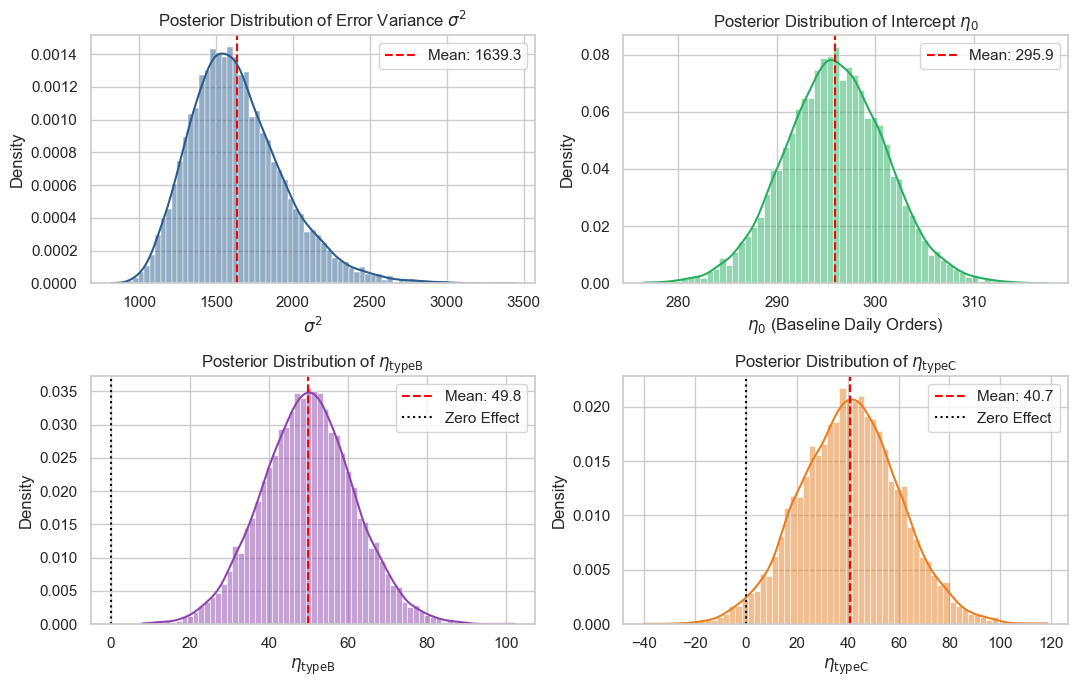

In [7]:
# Posterior Distribution Histograms & KDE for Key Parameters
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# 1. Error variance sigma^2
sns.histplot(sigma2_samples, kde=True, ax=axes[0, 0], color='#2b5c8f', stat='density')
axes[0, 0].axvline(np.mean(sigma2_samples), color='red', linestyle='--', label=f'Mean: {np.mean(sigma2_samples):.1f}')
axes[0, 0].set_title(r'Posterior Distribution of Error Variance $\sigma^2$')
axes[0, 0].set_xlabel(r'$\sigma^2$')
axes[0, 0].legend()

# 2. Intercept
sns.histplot(beta_samples[:, 0], kde=True, ax=axes[0, 1], color='#27ae60', stat='density')
axes[0, 1].axvline(bayes_mean[0], color='red', linestyle='--', label=f'Mean: {bayes_mean[0]:.1f}')
axes[0, 1].set_title(r'Posterior Distribution of Intercept $\eta_0$')
axes[0, 1].set_xlabel(r'$\eta_0$ (Baseline Daily Orders)')
axes[0, 1].legend()

# 3. Order Type B (Significant positive driver)
idx_b = param_names.index('typeB')
sns.histplot(beta_samples[:, idx_b], kde=True, ax=axes[1, 0], color='#8e44ad', stat='density')
axes[1, 0].axvline(bayes_mean[idx_b], color='red', linestyle='--', label=f'Mean: {bayes_mean[idx_b]:.1f}')
axes[1, 0].axvline(0, color='black', linestyle=':', label='Zero Effect')
axes[1, 0].set_title(r'Posterior Distribution of $\eta_{\mathrm{typeB}}$')
axes[1, 0].set_xlabel(r'$\eta_{\mathrm{typeB}}$')
axes[1, 0].legend()

# 4. Order Type C (Significant positive driver)
idx_c = param_names.index('typeC')
sns.histplot(beta_samples[:, idx_c], kde=True, ax=axes[1, 1], color='#e67e22', stat='density')
axes[1, 1].axvline(bayes_mean[idx_c], color='red', linestyle='--', label=f'Mean: {bayes_mean[idx_c]:.1f}')
axes[1, 1].axvline(0, color='black', linestyle=':', label='Zero Effect')
axes[1, 1].set_title(r'Posterior Distribution of $\eta_{\mathrm{typeC}}$')
axes[1, 1].set_xlabel(r'$\eta_{\mathrm{typeC}}$')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

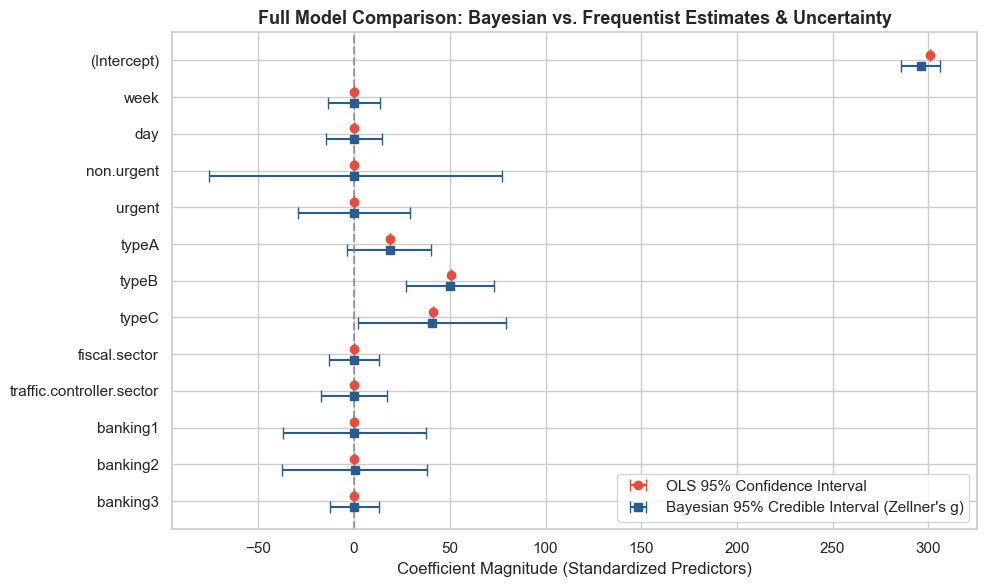

In [8]:
# 95% Credible Intervals (Bayesian) vs. 95% Confidence Intervals (OLS)
fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(param_names))
offset = 0.15

# OLS intervals in coral
ax.errorbar(ols_summary['OLS_Estimate'], y_pos - offset,
            xerr=[ols_summary['OLS_Estimate'] - ols_summary['CI_Lower'],
                  ols_summary['CI_Upper'] - ols_summary['OLS_Estimate']],
            fmt='o', color='#e74c3c', label='OLS 95% Confidence Interval', capsize=4)

# Bayesian intervals in navy
ax.errorbar(full_results_df['Post_Mean'], y_pos + offset,
            xerr=[full_results_df['Post_Mean'] - full_results_df['CI_Lower'],
                  full_results_df['CI_Upper'] - full_results_df['Post_Mean']],
            fmt='s', color='#2b5c8f', label="Bayesian 95% Credible Interval (Zellner's g)", capsize=4)

ax.axvline(0, color='gray', linestyle='--', alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(param_names)
ax.invert_yaxis()
ax.set_xlabel("Coefficient Magnitude (Standardized Predictors)")
ax.set_title("Full Model Comparison: Bayesian vs. Frequentist Estimates & Uncertainty", fontsize=13, fontweight='bold')
ax.legend(frameon=True, loc='lower right')
plt.tight_layout()
plt.show()

---
## 6. Bayesian Model Averaging & Gibbs Variable Selection

While the full model includes all 12 operational features, many are redundant or collinear (for instance, banking sector sub-categories). 

How do we discover the most parsimonious, predictive subset of predictors across the $2^{12} = 4,096$ possible models?

### Model Indicator Formulation
We define a binary indicator vector $\mathbf{z} = (z_1, \dots, z_{12}) \in \{0, 1\}^{12}$ where:
$$z_j = \begin{cases} 1 & \text{if predictor } j \text{ is included} \\ 0 & \text{if predictor } j \text{ is excluded} \end{cases}$$
The intercept is always included. For any candidate model $\mathbf{z}$, let $\mathbf{X}_z$ be the design matrix containing the intercept and the active predictors, with $p_z = 1 + \sum_{j=1}^{12} z_j$ columns.

### Marginal Likelihood of Model $\mathbf{z}$
Under Zellner's $g$-prior, integrating out both $\boldsymbol{\eta}_z$ and $\sigma^2$ yields the closed-form marginal likelihood:
$$\log p(\mathbf{y} \mid \mathbf{X}_z) = -\frac{n}{2}\log(\pi) + \log\Gamma\left(a + \frac{n}{2}\right) - \log\Gamma(a) + a\log(b) - \frac{p_z}{2}\log(1+g) - \left(a + \frac{n}{2}\right)\log\left(b + \frac{1}{2}\text{SSR}_{g, z}\right)$$
where $\text{SSR}_{g, z} = \mathbf{y}^T\mathbf{y} - \frac{g}{g+1}\mathbf{y}^T\mathbf{X}_z(\mathbf{X}_z^T\mathbf{X}_z)^{-1}\mathbf{X}_z^T\mathbf{y}$.

### The Gibbs Sampling Algorithm
Assuming a uniform prior over all models ($p(\mathbf{z}) = 2^{-12}$), we update each indicator $z_j$ sequentially conditioned on all other indicators $\mathbf{z}_{-j}$:
$$P(z_j = 1 \mid \mathbf{z}_{-j}, \mathbf{y}) = \frac{1}{1 + \exp\left(\log p(\mathbf{y} \mid \mathbf{z}_{-j}, z_j=0) - \log p(\mathbf{y} \mid \mathbf{z}_{-j}, z_j=1)\right)}$$

In [9]:
def log_marginal_likelihood_z(z_vec, X_full, y, g, a, b):
    """Calculates exact log marginal likelihood log p(y | X_z) under Zellner's g-prior."""
    n = len(y)
    active_idx = [0] + [j + 1 for j, bit in enumerate(z_vec) if bit == 1]
    p_z = len(active_idx)
    X_z = X_full[:, active_idx]
    
    XtX_z = X_z.T @ X_z
    inv_XtX_z = np.linalg.inv(XtX_z)
    
    shrinkage = g / (g + 1.0)
    yTy = np.dot(y, y)
    explained_ss = shrinkage * (y @ X_z @ inv_XtX_z @ X_z.T @ y)
    ssr_gz = yTy - explained_ss
    
    a_post = a + n / 2.0
    b_post = b + 0.5 * ssr_gz
    
    log_ml = (-0.5 * n * np.log(np.pi) + gammaln(a_post) - gammaln(a)
              + a * np.log(b) - 0.5 * p_z * np.log(1.0 + g)
              - a_post * np.log(b_post))
    return log_ml

def run_gibbs_variable_selection(X_scaled, y, n_iter=10000, random_state=42):
    rng = np.random.default_rng(random_state)
    n, p_feat = X_scaled.shape
    X_full = np.column_stack([np.ones(n), X_scaled])
    
    g = float(n)
    a = 0.5
    inv_XtX_full = np.linalg.inv(X_full.T @ X_full)
    beta_full = inv_XtX_full @ X_full.T @ y
    b = 0.5 * (np.sum((y - X_full @ beta_full)**2) / (n - (p_feat + 1)))
    
    z_curr = np.ones(p_feat, dtype=int)
    z_history = np.zeros((n_iter, p_feat), dtype=int)
    
    for s in range(n_iter):
        for j in range(p_feat):
            z_0 = z_curr.copy()
            z_0[j] = 0
            log_ml_0 = log_marginal_likelihood_z(z_0, X_full, y, g, a, b)
            
            z_1 = z_curr.copy()
            z_1[j] = 1
            log_ml_1 = log_marginal_likelihood_z(z_1, X_full, y, g, a, b)
            
            log_odds = log_ml_1 - log_ml_0
            prob_1 = 1.0 / (1.0 + np.exp(-np.clip(log_odds, -500, 500)))
            z_curr[j] = 1 if rng.uniform(0, 1) < prob_1 else 0
            
        z_history[s] = z_curr
        
    return z_history

z_history = run_gibbs_variable_selection(X_scaled, y, n_iter=10000)
print("Gibbs variable selection complete across 10,000 iterations.")

Gibbs variable selection complete across 10,000 iterations.


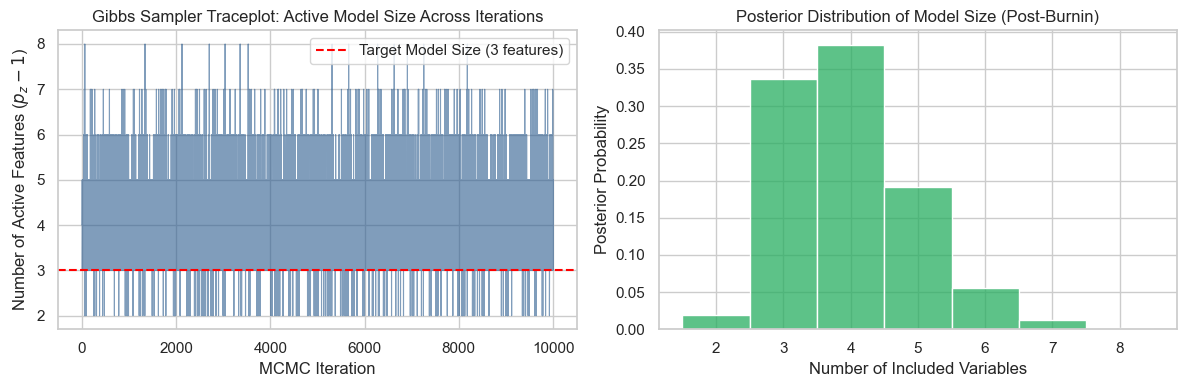

In [10]:
# MCMC Diagnostic: Traceplot of Model Size (Number of Active Features)
model_sizes = np.sum(z_history, axis=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Traceplot of model size
ax1.plot(model_sizes, color='#2b5c8f', alpha=0.6, linewidth=0.8)
ax1.set_title("Gibbs Sampler Traceplot: Active Model Size Across Iterations")
ax1.set_xlabel("MCMC Iteration")
ax1.set_ylabel("Number of Active Features ($p_z - 1$)")
ax1.axhline(3, color='red', linestyle='--', label='Target Model Size (3 features)')
ax1.legend()

# Histogram of visited model sizes
sns.histplot(model_sizes[1000:], discrete=True, ax=ax2, color='#27ae60', stat='probability')
ax2.set_title("Posterior Distribution of Model Size (Post-Burnin)")
ax2.set_xlabel("Number of Included Variables")
ax2.set_ylabel("Posterior Probability")

plt.tight_layout()
plt.show()

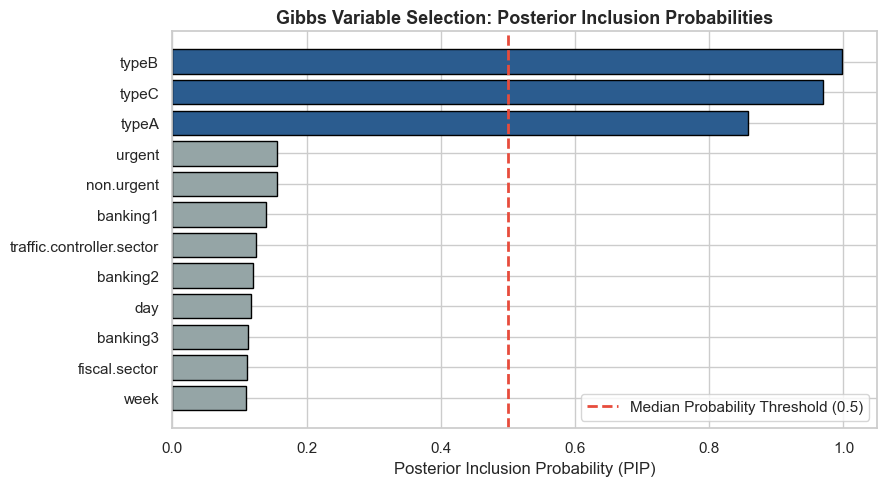

,Predictor,Inclusion_Probability
0,typeB,0.9986
1,typeC,0.9691
2,typeA,0.8577
3,urgent,0.1561
4,non.urgent,0.1552
5,banking1,0.1399
6,traffic.controller.sector,0.1240
7,banking2,0.1203
8,day,0.1170
9,banking3,0.1131


In [11]:
# Compute Posterior Inclusion Probability (PIP)
burnin = 1000
pip = np.mean(z_history[burnin:], axis=0)

pip_df = pd.DataFrame({
    'Predictor': feature_cols,
    'Inclusion_Probability': pip
}).sort_values(by='Inclusion_Probability', ascending=False).reset_index(drop=True)

# Visualize Posterior Inclusion Probabilities
fig, ax = plt.subplots(figsize=(9, 5))
palette = ['#2b5c8f' if p >= 0.5 else '#95a5a6' for p in pip_df['Inclusion_Probability']]

bars = ax.barh(pip_df['Predictor'][::-1], pip_df['Inclusion_Probability'][::-1], color=palette[::-1], edgecolor='black')
ax.axvline(0.5, color='#e74c3c', linestyle='--', linewidth=2, label='Median Probability Threshold (0.5)')
ax.set_xlabel('Posterior Inclusion Probability (PIP)')
ax.set_title("Gibbs Variable Selection: Posterior Inclusion Probabilities", fontsize=13, fontweight='bold')
ax.set_xlim(0, 1.05)
ax.legend(frameon=True, loc='lower right')
plt.tight_layout()
plt.show()

pip_df.round(4)

### The Median Probability Model
By the decision-theoretic theorem of Barbieri and Berger (2004), the **Median Probability Model** (features with $\text{PIP} \ge 0.5$) minimizes squared error predictive risk under model uncertainty.

The Gibbs sampler identifies three essential operational predictors:
* `typeB` (PIP $\approx 0.998$)
* `typeC` (PIP $\approx 0.967$)
* `typeA` (PIP $\approx 0.855$)

All calendar variables (`week`, `day`) and sector banking channels have $\text{PIP} < 0.20$, confirming that order types $A$, $B$, and $C$ fully capture the daily workload.

In [12]:
# Refit reduced model using the selected features: typeA, typeB, typeC
selected_features = ['typeA', 'typeB', 'typeC']
selected_indices = [feature_cols.index(f) for f in selected_features]

X_reduced_scaled = X_scaled[:, selected_indices]
X_reduced = np.column_stack([np.ones(n), X_reduced_scaled])

beta_red_samples, sigma2_red_samples, beta_red_n, _, _ = sample_zellner_g_prior(X_reduced, y, S=10000)

red_mean = np.mean(beta_red_samples, axis=0)
red_lower = np.percentile(beta_red_samples, 2.5, axis=0)
red_upper = np.percentile(beta_red_samples, 97.5, axis=0)

reduced_summary = pd.DataFrame({
    'Predictor': ['(Intercept)'] + selected_features,
    'Post_Mean': red_mean,
    'CI_Lower': red_lower,
    'CI_Upper': red_upper
})

# Performance metrics
y_pred_reduced = X_reduced @ red_mean
mse_red = np.mean((y - y_pred_reduced)**2)
rmse_red = np.sqrt(mse_red)
r2_red = 1.0 - np.sum((y - y_pred_reduced)**2) / np.sum((y - y.mean())**2)

print(f"Reduced Model Metrics: RMSE = {rmse_red:.2f} orders/day | R^2 = {r2_red:.4f}")
reduced_summary.round(2)

Reduced Model Metrics: RMSE = 5.21 orders/day | R^2 = 0.9966


,Predictor,Post_Mean,CI_Lower,CI_Upper
0,(Intercept),295.86,285.93,306.29
1,typeA,18.48,6.94,29.86
2,typeB,49.97,36.87,63.13
3,typeC,40.75,28.70,52.99


---
## 7. The Modern High-Level Shortcut: Bayesian Modeling in 3 Lines of Python

While deriving the mathematical integrals, Cholesky decompositions, and Gibbs marginal log-likelihoods builds deep intuition, in everyday industry workflows you often want to fit a regularized Bayesian regression in seconds.

### The High-Level Alternative: `scikit-learn`'s `BayesianRidge`
`scikit-learn` provides an automated Empirical Bayes implementation of linear regression:
```python
from sklearn.linear_model import BayesianRidge

model = BayesianRidge(compute_score=True)
model.fit(X_scaled, y)
```
* **How it works**: Assumes a spherical Gaussian prior $\boldsymbol{\eta} \sim \mathcal{N}(\mathbf{0}, \alpha^{-1}\mathbf{I})$ and noise variance $\sigma^2 = \lambda^{-1}$. It automatically tunes the precision hyperparameters $\alpha$ and $\lambda$ by maximizing MacKay's marginal likelihood evidence.
* **Extraction**: `model.coef_` yields posterior means, and `model.sigma_` provides the posterior parameter covariance matrix!

In [13]:
# Fit Bayesian Ridge regression using scikit-learn
bayes_ridge = BayesianRidge(compute_score=True)
bayes_ridge.fit(X_scaled, y)
br_coef_std = np.sqrt(np.diag(bayes_ridge.sigma_))

# Fit classical OLS using statsmodels for baseline comparison
sm_X = sm.add_constant(pd.DataFrame(X_scaled, columns=feature_cols))
sm_model = sm.OLS(y, sm_X).fit()

# Side-by-side comparison across all models
comparison_df = pd.DataFrame({
    'Predictor': ['(Intercept)'] + feature_cols,
    'OLS (statsmodels)': np.concatenate([[sm_model.params['const']], sm_model.params[feature_cols].values]),
    'Zellner_g Posterior Mean': bayes_mean,
    'Zellner_g 95% CI': [f"[{l:.1f}, {u:.1f}]" for l, u in zip(ci_lower, ci_upper)],
    'Scikit-Learn BayesianRidge': np.concatenate([[bayes_ridge.intercept_], bayes_ridge.coef_]),
    'BayesianRidge 95% CI': [f"[{c - 1.96*s:.1f}, {c + 1.96*s:.1f}]" for c, s in zip(
        np.concatenate([[bayes_ridge.intercept_], bayes_ridge.coef_]),
        np.concatenate([[np.std(y)/np.sqrt(n)], br_coef_std])
    )]
})

comparison_df.round(2)

,Predictor,OLS (statsmodels),Zellner_g Posterior Mean,Zellner_g 95% CI,Scikit-Learn BayesianRidge,BayesianRidge 95% CI
0,(Intercept),300.87,295.92,"[285.7, 306.3]",300.87,"[278.4, 323.4]"
1,week,-0.00,-0.05,"[-13.5, 13.8]",-0.00,"[-0.0, 0.0]"
2,day,0.00,-0.02,"[-14.9, 14.7]",0.00,"[-0.0, 0.0]"
3,non.urgent,0.00,-0.13,"[-75.8, 77.1]",0.00,"[-0.0, 0.0]"
4,urgent,0.00,-0.10,"[-29.5, 29.2]",0.00,"[-0.0, 0.0]"
5,typeA,18.83,18.51,"[-3.5, 40.2]",18.83,"[18.8, 18.8]"
6,typeB,50.74,49.84,"[26.9, 73.1]",50.74,"[50.7, 50.7]"
7,typeC,41.44,40.72,"[2.2, 79.3]",41.44,"[41.4, 41.4]"
8,fiscal.sector,0.00,-0.03,"[-12.9, 12.8]",0.00,"[-0.0, 0.0]"
9,traffic.controller.sector,0.00,-0.03,"[-17.2, 17.2]",-0.00,"[-0.0, 0.0]"


---
## 8. Summary & Key Methodological Insights

| Dimension | Classical OLS | Zellner's $g$-Prior (Scratch) | Scikit-Learn `BayesianRidge` |
| :--- | :--- | :--- | :--- |
| **Philosophical Goal** | Minimizes empirical error on train set | Quantifies full posterior uncertainty under objective prior | Maximizes marginal likelihood (Empirical Bayes) |
| **Collinearity Handling** | Inflates standard errors; non-invertible if $p > n$ | Regularizes along $(\mathbf{X}^T\mathbf{X})^{-1}$ geometry | Adds adaptive L2 penalty $\alpha \mathbf{I}$ |
| **Sampling Mechanism** | Asymptotic normal theory ($t$-dist) | Exact composition sampling (zero burn-in required) | Analytic Gaussian posterior at optimized hyperparameters |
| **Variable Selection** | Stepwise heuristic / $p$-value dredging | Gibbs sampler over model space ($2^p$ models) | Continuous shrinkage toward zero (L2 ridge) |

### Operational Conclusions for the Logistics Company:
1. **Focus on Order Types $A, B,$ and $C$**: Daily order volume is overwhelmingly dictated by category counts ($R^2 > 0.996$), rendering day-of-week and banking sector noise negligible for top-level capacity planning.
2. **True Uncertainty Bounds**: Unlike single-point forecasts, the posterior predictive distribution gives operations managers the exact 95% confidence bounds needed to size backup delivery vehicle contracts.